# O melhor time é feito dos melhores jogadores?

Esta análise usa o [MEM-GA](README.md) para responder a essa pergunta com dados do Campeonato Brasileiro de 2017. Em vez de somar os jogadores mais fortes, o método procura o grupo que se complementa melhor.

As estatísticas são comparadas por 90 minutos, entre jogadores com pelo menos 850 minutos em campo.

In [1]:
from collections import Counter
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np

from mem_ga import PRESETS, build_scorer, load_dataset, run_ga

BLUE, GRAY, INK, MUTED, LINE = "#2a78d6", "#a5a39c", "#0b0b0b", "#52514e", "#dcdad3"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.edgecolor": LINE,
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.titlelocation": "left",
    "axes.titlecolor": INK,
})
Path("images").mkdir(exist_ok=True)

dataset = load_dataset()
scorer = build_scorer(dataset, 10)
strengths = dataset.payment.sum(axis=1)

## Os dados

In [2]:
positions = Counter(dataset.positions.tolist())
print(f"Jogadores de linha: {len(dataset.players)}")
print(f"Critérios: {len(dataset.criteria)}")
print(f"Combinações de 10 critérios: {scorer.combo_matrix.shape[1]}")
for position, amount in positions.most_common():
    print(f"  {position}: {amount}")

Jogadores de linha: 317
Critérios: 18
Combinações de 10 critérios: 43758
  VOL: 67
  ATA: 65
  ZAG: 63
  MEI: 57
  LE: 35
  LD: 30


## Os times de cada formação

A nota é a fração das combinações de critérios em que o time alcança o tau de 0,36.

In [3]:
formations = {"Livre": None, **PRESETS}
results = {
    name: run_ga(scorer, dataset.positions, quotas, 10, seed=0)
    for name, quotas in formations.items()
}

for name, result in results.items():
    print(f"{name:8s} nota {result.score:.4f}")

Livre    nota 0.8997
4-4-2    nota 0.8619
4-3-3    nota 0.8654
4-2-3-1  nota 0.8382
3-5-2    nota 0.8165


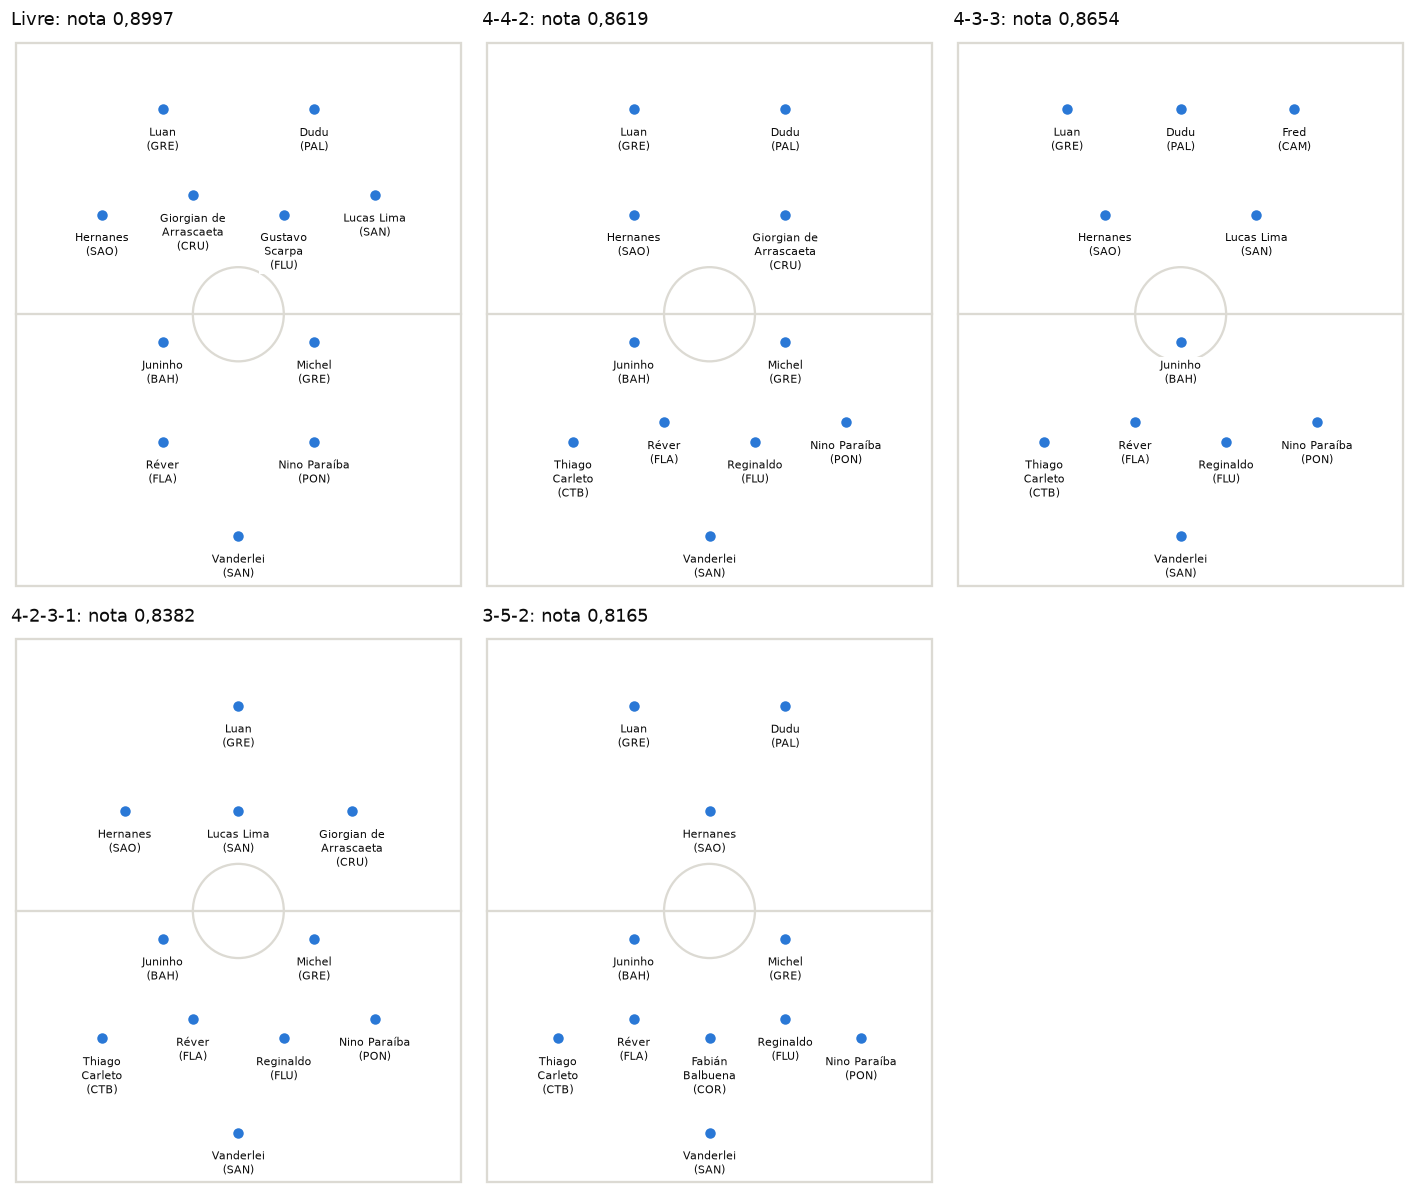

In [4]:
ROWS = [("ATA",), ("MEI",), ("VOL",), ("LE", "ZAG", "LD")]
HEIGHTS = [0.87, 0.68, 0.45, 0.27]


def label(name):
    player, club = name.rsplit(" (", 1)
    return f"{fill(player, 13)}\n({club}"


def draw_pitch(axes, team, title):
    axes.set_xlim(0, 1)
    axes.set_ylim(0, 1)
    axes.axis("off")
    axes.add_patch(plt.Rectangle((0.01, 0.01), 0.98, 0.98, fill=False, edgecolor=LINE, linewidth=1.5))
    axes.plot([0.01, 0.99], [0.5, 0.5], color=LINE, linewidth=1.5, zorder=0)
    axes.add_patch(Ellipse((0.5, 0.5), 0.2, 0.17, fill=False, edgecolor=LINE, linewidth=1.5))
    axes.set_title(title, fontsize=12, pad=8)

    for row, height in zip(ROWS, HEIGHTS):
        players = sorted(
            (player for player in team if dataset.positions[player] in row),
            key=lambda player: (row.index(dataset.positions[player]), -strengths[player]),
        )
        for index, player in enumerate(players):
            x = (index + 1) / (len(players) + 1)
            y = height + (0.035 if len(players) > 3 and index % 2 else 0)
            draw_player(axes, x, y, dataset.players[player])
    draw_player(axes, 0.5, 0.1, dataset.goalkeeper)


def draw_player(axes, x, y, name):
    axes.scatter([x], [y], s=70, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
    axes.text(x, y - 0.03, label(name), ha="center", va="top", fontsize=7.5, color=INK, zorder=4,
              bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.8})


figure, grid = plt.subplots(2, 3, figsize=(13, 11))
for axes, (name, result) in zip(grid.flat, results.items()):
    score = f"{result.score:.4f}".replace(".", ",")
    draw_pitch(axes, result.team, f"{name}: nota {score}")
grid.flat[-1].axis("off")
figure.tight_layout()
figure.savefig("images/times.png", dpi=130, bbox_inches="tight", facecolor="white")
plt.show()

Luan, Hernanes, Juninho, Réver e Nino Paraíba aparecem em todas as formações. O time livre tem a maior nota porque não precisa cumprir quotas, e nele só dois jogadores ficam na defesa.

## Complementar não é somar os melhores

Aqui, o time livre é comparado com os 10 jogadores que atingem mais critérios individualmente.

In [5]:
strongest = np.argsort(-strengths, kind="stable")[:10].tolist()
complementary = list(results["Livre"].team)

print(f"10 jogadores com mais critérios: nota {scorer.rate(strongest)[0]:.4f}")
print(f"Time mais complementar:          nota {results['Livre'].score:.4f}")
print(f"Jogadores em comum: {len(set(strongest) & set(complementary))} de 10")
print("Só nos mais fortes:", ", ".join(dataset.players[p] for p in strongest if p not in complementary))
print("Só no complementar:", ", ".join(dataset.players[p] for p in complementary if p not in strongest))

10 jogadores com mais critérios: nota 0.8567
Time mais complementar:          nota 0.8997
Jogadores em comum: 7 de 10
Só nos mais fortes: Juan Cazares (CAM), Fred (CAM), Neilton (VIT)
Só no complementar: Nino Paraíba (PON), Michel (GRE), Réver (FLA)


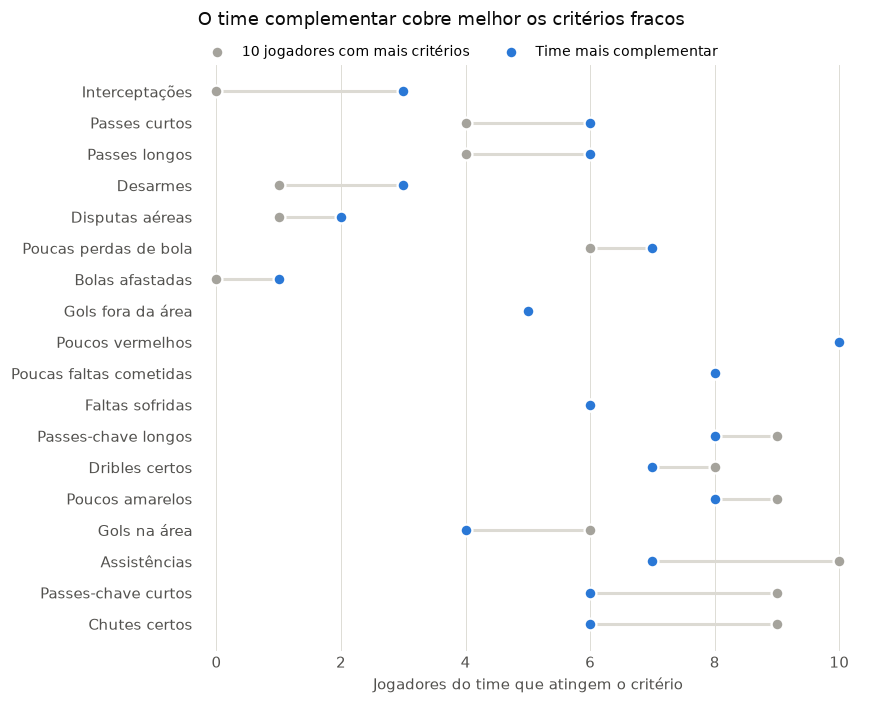

In [6]:
NAMES = {
    "Tackles": "Desarmes", "Interception": "Interceptações", "Fouled": "Faltas sofridas",
    "Fouls": "Poucas faltas cometidas", "Yellow": "Poucos amarelos", "Red": "Poucos vermelhos",
    "Clearences": "Bolas afastadas", "ShotsW": "Chutes certos", "GolsA": "Gols na área",
    "GolsFA": "Gols fora da área", "DribblesSuccessful": "Dribles certos",
    "PossLost": "Poucas perdas de bola", "AerialWon": "Disputas aéreas", "AccLB": "Passes longos",
    "AccSP": "Passes curtos", "KPLong": "Passes-chave longos", "KPShort": "Passes-chave curtos",
    "AssistsTotal": "Assistências",
}
weak = dataset.payment[strongest].sum(axis=0)
strong = dataset.payment[complementary].sum(axis=0)
order = np.argsort(strong - weak, kind="stable")
y = np.arange(len(order))

figure, axes = plt.subplots(figsize=(8, 6.5))
axes.hlines(y, weak[order], strong[order], color=LINE, linewidth=2, zorder=1)
axes.scatter(weak[order], y, s=60, color=GRAY, edgecolor="white", linewidth=1.5, zorder=2,
             label="10 jogadores com mais critérios")
axes.scatter(strong[order], y, s=60, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3,
             label="Time mais complementar")
axes.set_yticks(y, [NAMES[dataset.criteria[i]] for i in order])
axes.set_xlim(-0.3, 10.3)
axes.set_xlabel("Jogadores do time que atingem o critério")
axes.set_title("O time complementar cobre melhor os critérios fracos", pad=26)
axes.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2, frameon=False, borderaxespad=0, fontsize=9)
axes.grid(axis="x", color=LINE, linewidth=0.6)
axes.set_axisbelow(True)
axes.tick_params(length=0)
axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
figure.tight_layout()
figure.savefig("images/cobertura.png", dpi=130, bbox_inches="tight", facecolor="white")
plt.show()

Os dois times têm 7 jogadores em comum. Ao trocar Cazares, Fred e Neilton por Nino Paraíba, Michel e Réver, o time perde um pouco de ataque e ganha em interceptações, desarmes e passes. A nota do grupo sobe de 0,8567 para 0,8997, mesmo com menos força individual.

## Como o algoritmo chega lá

Quase todo time sorteado tem nota zero. O gráfico mostra a melhor nota encontrada a cada iteração.

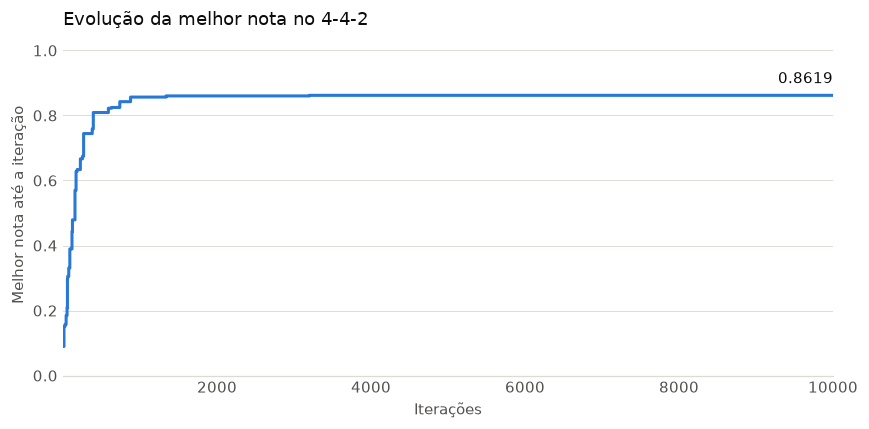

In [7]:
history = results["4-4-2"].history
iterations = np.arange(1, len(history) + 1)

figure, axes = plt.subplots(figsize=(8, 4))
axes.step(iterations, history, where="post", color=BLUE, linewidth=2)
axes.annotate(f"{history[-1]:.4f}", (iterations[-1], history[-1]), xytext=(0, 8),
              textcoords="offset points", ha="right", color=INK)
axes.set_title("Evolução da melhor nota no 4-4-2")
axes.set_xlabel("Iterações")
axes.set_ylabel("Melhor nota até a iteração")
axes.set_xlim(1, len(history))
axes.set_ylim(0, 1.05)
axes.grid(axis="y", color=LINE, linewidth=0.6)
axes.set_axisbelow(True)
axes.tick_params(length=0)
axes.spines[["top", "right", "left"]].set_visible(False)
figure.tight_layout()
plt.show()

A nota sobe rápido no início, quando o algoritmo sai dos times sorteados. Depois, ela melhora em degraus, a cada vez que o cruzamento ou a mutação encontra um time melhor.

## Quem aparece em todas as formações

Os jogadores que se repetem são os que continuam úteis quando a estrutura do time muda.

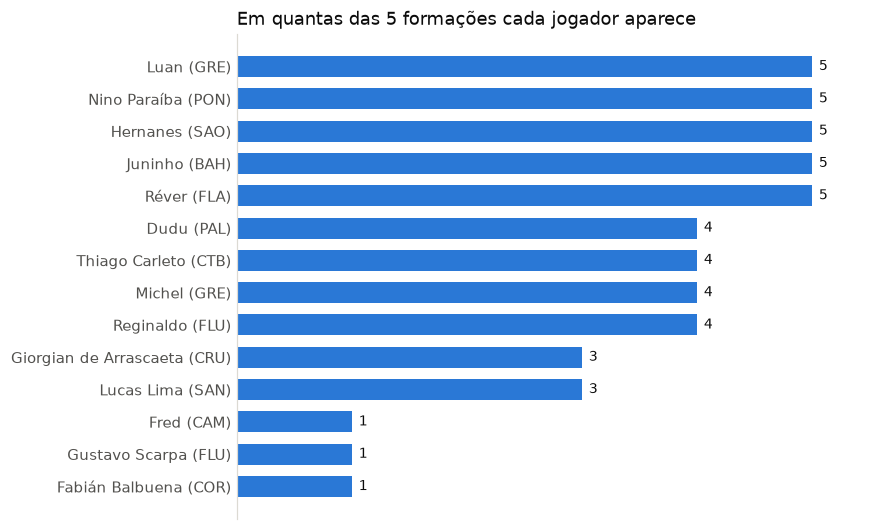

In [8]:
presence = Counter(player for result in results.values() for player in result.team)
ranking = sorted(presence.items(), key=lambda item: (item[1], -item[0]))
names = [dataset.players[player] for player, _ in ranking]
counts = [count for _, count in ranking]

figure, axes = plt.subplots(figsize=(8, 0.28 * len(names) + 1))
axes.barh(names, counts, color=BLUE, height=0.65)
for index, count in enumerate(counts):
    axes.text(count + 0.06, index, str(count), va="center", color=INK, fontsize=9)
axes.set_xlim(0, 5.4)
axes.set_xticks([])
axes.set_title("Em quantas das 5 formações cada jogador aparece")
axes.tick_params(length=0)
axes.spines[["top", "right", "bottom"]].set_visible(False)
figure.tight_layout()
plt.show()

Cinco jogadores aparecem nas cinco formações, e outros quatro aparecem em quatro delas.

## O goleiro

O goleiro não entra nas combinações, porque suas estatísticas são outras. Ele é escolhido pelo aproveitamento de defesas: defesas divididas pela soma de defesas e gols sofridos.

In [9]:
import csv

with open("data/goalkeepers.csv", encoding="utf-8") as file:
    keepers = [row for row in csv.DictReader(file) if int(row["minutes"]) >= 850]
for row in keepers:
    row["rate"] = int(row["saves"]) / (int(row["saves"]) + int(row["goals_conceded"]))

print(f"{'Goleiro':24s} {'Defesas':>8s} {'Gols':>6s} {'Aproveitamento':>15s}")
for row in sorted(keepers, key=lambda item: -item["rate"])[:5]:
    name = f"{row['player']} ({row['team']})"
    print(f"{name:24s} {row['saves']:>8s} {row['goals_conceded']:>6s} {row['rate']:>15.1%}")

Goleiro                   Defesas   Gols  Aproveitamento
Vanderlei (SAN)               135     32           80.8%
Marcelo Grohe (GRE)            51     14           78.5%
Cássio (COR)                  105     29           78.4%
Marcos (ACG)                   44     13           77.2%
Douglas Friedrich (AVA)       114     34           77.0%
